# Linear Regression

## Introduction

**Linear Regression** is a supervised machine learning algorithm used to predict continuous numerical values by establishing a linear relationship between independent variables (features) and a dependent variable (target).

Examples include predicting house prices, salaries, and wine quality scores.
## How Linear Regression Works

1. **Input features:** The model receives independent variables (X) and a target variable (y).
2. **Find relationships:** It learns how changes in the input features relate to the target.
3. **Fit the model:** It estimates coefficients and an intercept to find the best-fitting linear relationship.
4. **Make predictions:** It uses the learned relationship to predict values for new data.
5. **Evaluate performance:** Predictions are compared with actual values using regression metrics.

Linear Regression commonly uses **Ordinary Least Squares (OLS)** to minimize the sum of squared differences between actual and predicted values.

## Mathematical Representation
### Simple Linear Regression

$$
y = \beta_0 + \beta_1x + \epsilon
$$

### Multiple Linear Regression

$$
y = \beta_0 + \beta_1x_1 + \beta_2x_2 + \cdots + \beta_nx_n + \epsilon
$$

Where:
- $y$: Target variable.
- $x$: Input feature(s).
- $\beta_0$: Intercept.
- $\beta_1, \ldots, \beta_n$: Feature coefficients.
- $\epsilon$: Error term.

## Key Points

- **Supervised learning:** Requires labelled training data.
- **Regression:** Predicts continuous numerical values.
- **OLS:** Minimizes the sum of squared residuals.
- **Coefficients:** Indicate how features relate to the predicted target.
- **Assumption:** The expected relationship between features and target is linear.

## Advantages and Limitations

**Advantages:** Simple, interpretable, computationally efficient, and useful as a baseline model.

**Limitations:** Sensitive to outliers, struggles with complex nonlinear relationships, and can be affected by multicollinearity.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_california_housing # dataset loading
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

# Random Dataset

In [45]:
# generate random dataset
np.random.seed(42)

X = np.random.rand(50, 1) * 100  

Y = 3.5 * X + np.random.randn(50, 1) * 20

In [47]:
# Creating and Training Linear Regression Model
model = LinearRegression()
model.fit(X, Y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [48]:
# Predicting Y Values
Y_pred = model.predict(X)

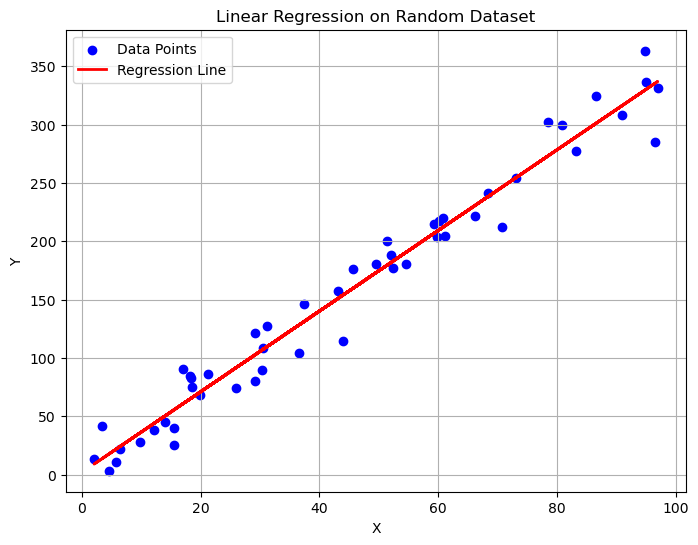

In [49]:
# best-fit regression line
plt.figure(figsize=(8,6)) 
plt.scatter(X, Y, color='blue', label='Data Points') 
plt.plot(X, Y_pred, color='red', linewidth=2, label='Regression Line') 
plt.title('Linear Regression on Random Dataset')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.show()

In [50]:
# Slope and Intercept
print("Slope (Coefficient):", model.coef_[0][0])
print("Intercept:", model.intercept_[0])

Slope (Coefficient): 3.4553132007706204
Intercept: 1.9337854893777546


# California Housing

In [4]:
# Load California Housing dataset
from sklearn.datasets import fetch_california_housing
housing = fetch_california_housing(as_frame=True)
# Separate features and target
df = housing.frame
print(df.shape)
df.head()

(20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [5]:
# dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [6]:
# summary stats
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
# check missing values
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [9]:
# check duplicates
df.duplicated().sum()

np.int64(0)

In [10]:
# separate features and target
X = df.drop(columns = 'MedHouseVal')
y = df['MedHouseVal']
print(X.shape)
y.shape

(20640, 8)


(20640,)

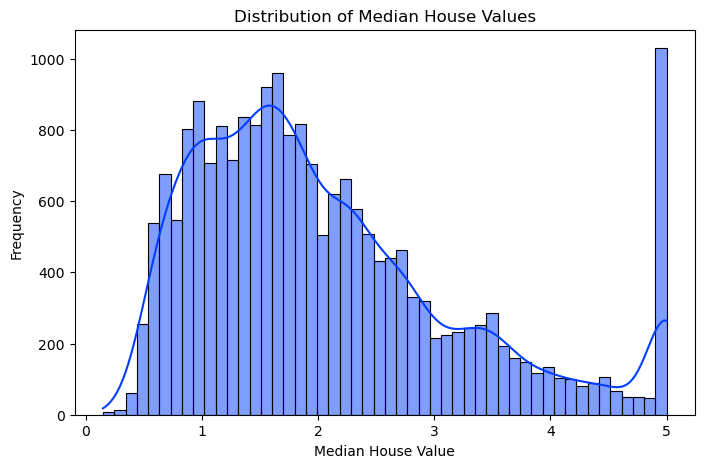

In [23]:
# distribution of target variable
plt.figure(figsize = (8,5))
sns.histplot(y,bins = 50, kde = True ,color=sns.color_palette("bright")[0])
plt.title('Distribution of Median House Values')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')
plt.show()

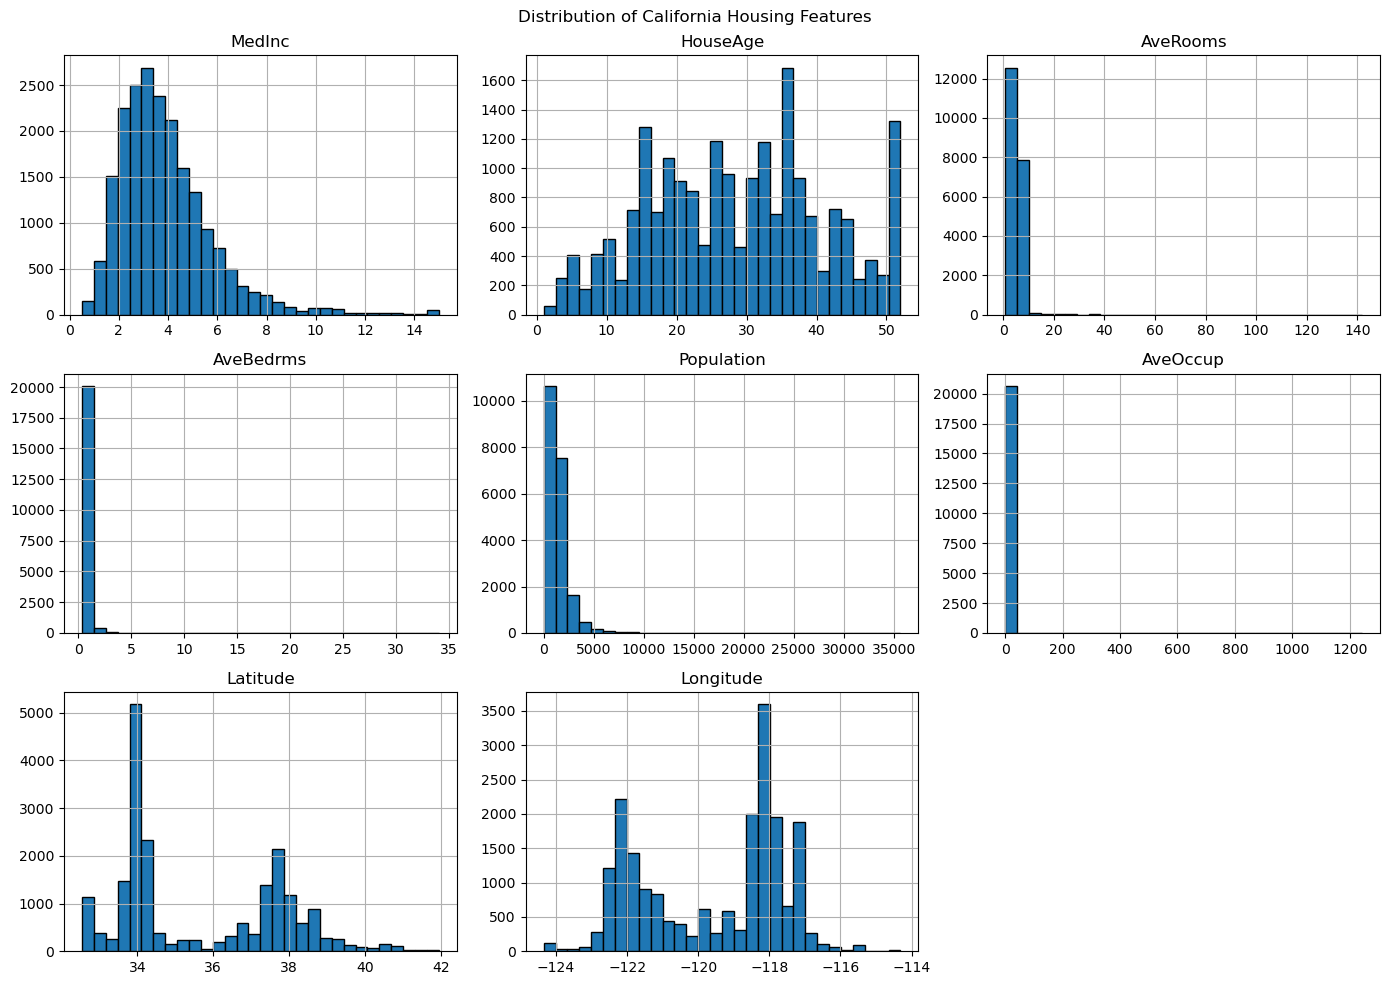

In [24]:
# distribution of numerical features
X.hist(figsize=(14, 10), bins=30, edgecolor='black')

plt.suptitle('Distribution of California Housing Features')
plt.tight_layout()
plt.show()

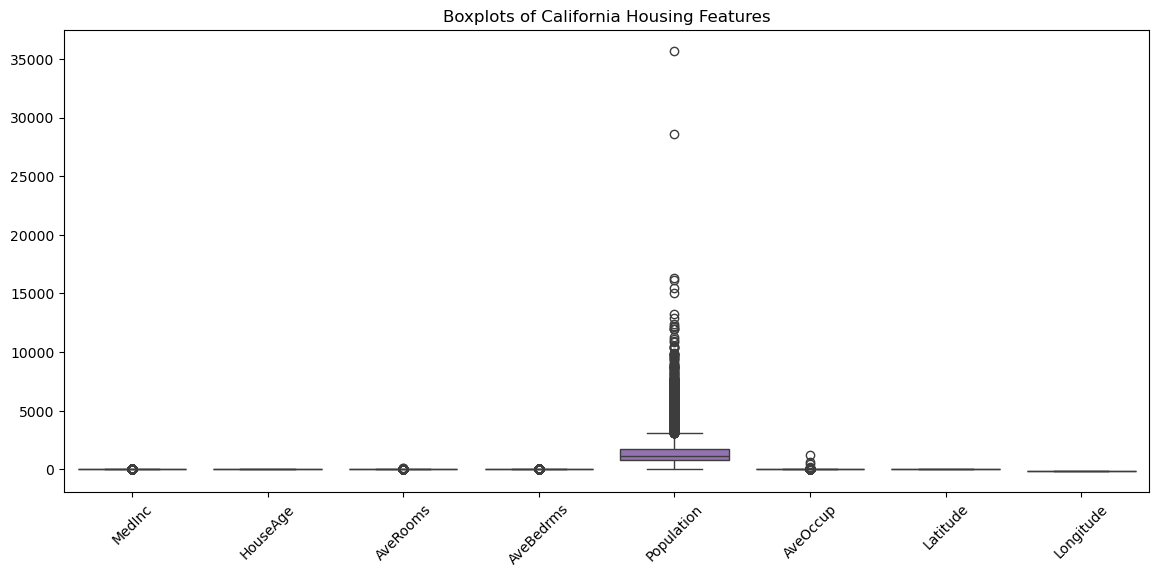

In [25]:
# outliers 
plt.figure(figsize=(14, 6))

sns.boxplot(data=X)

plt.title('Boxplots of California Housing Features')
plt.xticks(rotation=45)
plt.show()

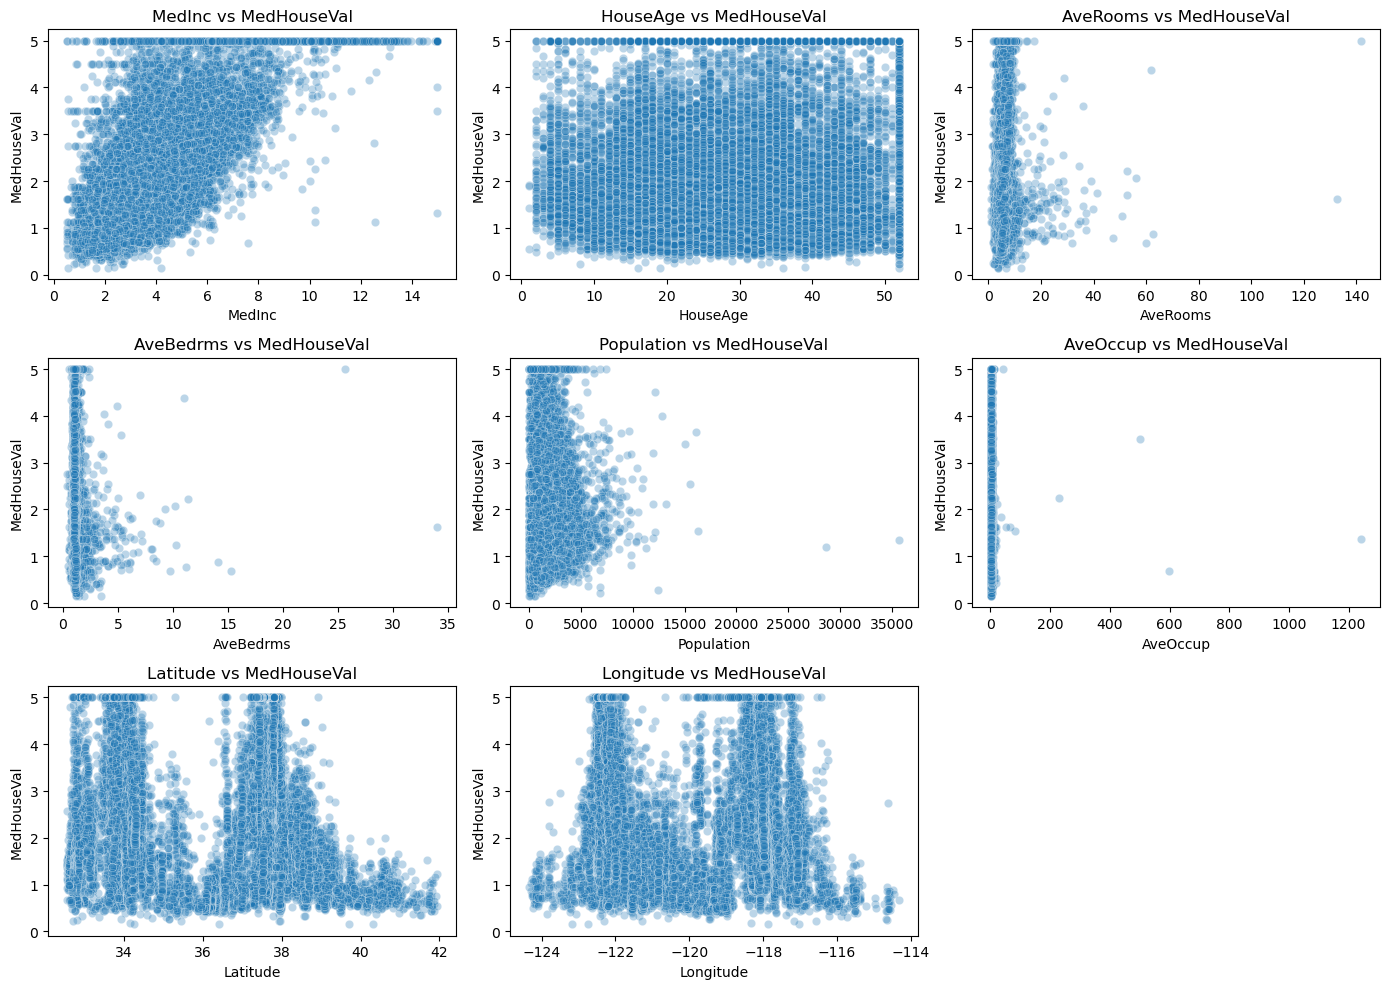

In [27]:
# feature rlship with target
plt.figure(figsize=(14, 10))

for i, column in enumerate(X.columns, 1):
    plt.subplot(3, 3, i)
    sns.scatterplot(x=X[column], y=y, alpha=0.3)
    plt.title(f'{column} vs MedHouseVal')
    plt.xlabel(column)
    plt.ylabel('MedHouseVal')

plt.tight_layout()
plt.show()

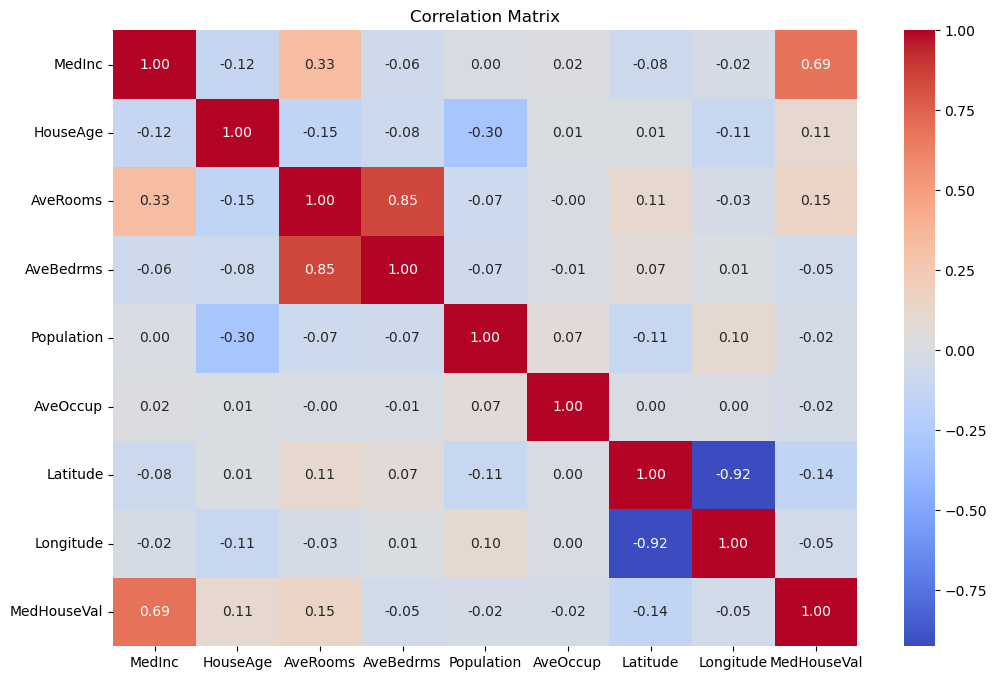

In [30]:
# correlation analysis
plt.figure(figsize = (12,8))
corr = df.corr()
sns.heatmap(corr,annot = True,cmap = 'coolwarm',fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

####  EDA summary

- MedInc shows a strong positive correlation with MedHouseVal.
- Housing values generally increase as median income increases.
- Some features contain potential outliers.
- Features have different scales and distributions.
- Some relationships between features and the target may be nonlinear.

In [31]:
# preprocessing
# separate features  and target
X = df.drop(columns = 'MedHouseVal')
y = df['MedHouseVal']
print(X.shape)
y.shape

(20640, 8)


(20640,)

In [32]:
# split dataset
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.2,random_state = 42)
print(X_train.shape)
X_test.shape

(16512, 8)


(4128, 8)

In [34]:
# Modelling
lr = LinearRegression()
lr.fit(X_train,y_train) # train model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [41]:
# predictions
y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

In [37]:
# coefficients
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', ascending=False)

coefficients

,Feature,Coefficient
3,AveBedrms,0.783145
0,MedInc,0.448675
1,HouseAge,0.009724
4,Population,-0.000002
5,AveOccup,-0.003526
2,AveRooms,-0.123323
6,Latitude,-0.419792
7,Longitude,-0.433708


In [39]:
# intercept
lr.intercept_

np.float64(-37.023277706064235)

In [42]:
# Evaluation
# Training metrics
train_mae = mean_absolute_error(y_train, y_train_pred)
train_mse = mean_squared_error(y_train, y_train_pred)
train_rmse = np.sqrt(train_mse)
train_r2 = r2_score(y_train, y_train_pred)
# Testing metrics
test_mae = mean_absolute_error(y_test, y_test_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, y_test_pred)

results = pd.DataFrame({
    'Metric': ['MAE', 'MSE', 'RMSE', 'R²'],
    'Training': [train_mae, train_mse, train_rmse, train_r2],
    'Testing': [test_mae, test_mse, test_rmse, test_r2]
})

results

,Metric,Training,Testing
0,MAE,0.528628,0.533200
1,MSE,0.517933,0.555892
2,RMSE,0.719676,0.745581
3,R²,0.612551,0.575788


### Evaluation Observations
- The model achieved a testing R² score of approximately 0.576.
- Training and testing errors are relatively close, suggesting reasonable generalization.
- The model explains about 57.6% of the variation in median house values.
- The prediction errors indicate that there is room for improvement.

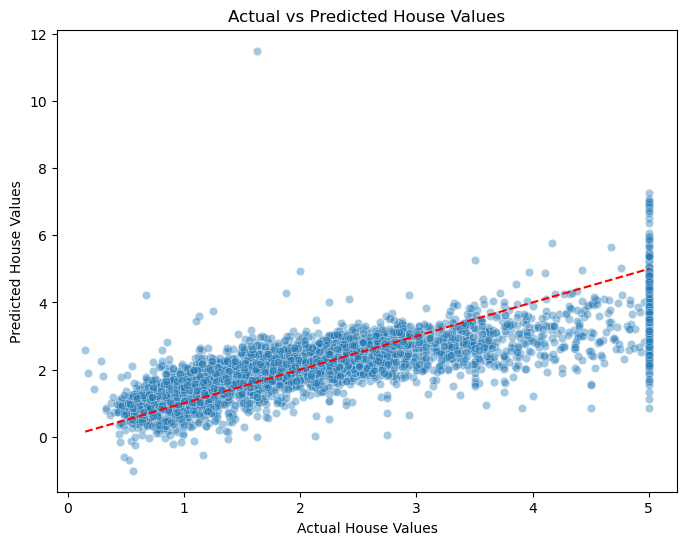

In [43]:
# Actual vs predicted
plt.figure(figsize=(8, 6))

sns.scatterplot(x=y_test, y=y_test_pred, alpha=0.4)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linestyle='--'
)

plt.xlabel('Actual House Values')
plt.ylabel('Predicted House Values')
plt.title('Actual vs Predicted House Values')
plt.show()

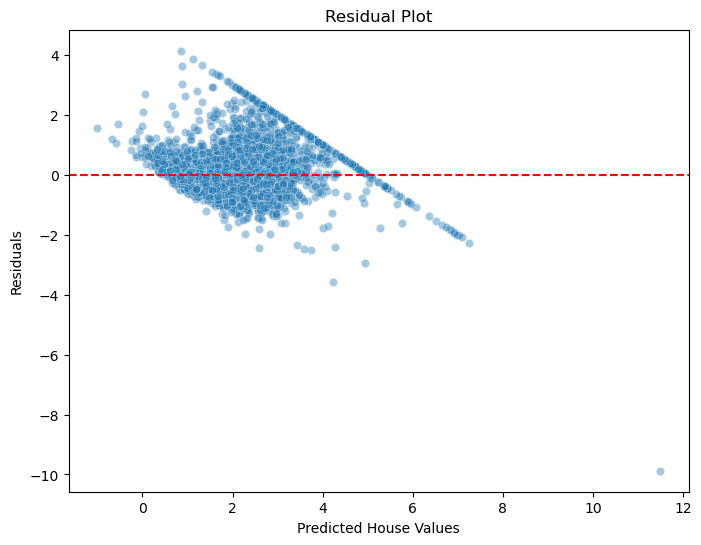

In [44]:
# Residual
residuals = y_test - y_test_pred

plt.figure(figsize=(8, 6))
sns.scatterplot(x=y_test_pred, y=residuals, alpha=0.4)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted House Values')
plt.ylabel('Residuals')
plt.title('Residual Plot')
plt.show()

In [91]:
import statsmodels.api as sm

X_train_sm = sm.add_constant(X_train)

california_ols = sm.OLS(y_train, X_train_sm).fit()

print(california_ols.summary())

                            OLS Regression Results                            
Dep. Variable:            MedHouseVal   R-squared:                       0.613
Model:                            OLS   Adj. R-squared:                  0.612
Method:                 Least Squares   F-statistic:                     3261.
Date:                Mon, 26 Oct 2026   Prob (F-statistic):               0.00
Time:                        04:07:49   Log-Likelihood:                -17998.
No. Observations:               16512   AIC:                         3.601e+04
Df Residuals:                   16503   BIC:                         3.608e+04
Df Model:                           8                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        -37.0233      0.728    -50.835      0.0

ValueError: X has 2 features, but LinearRegression is expecting 1 features as input.

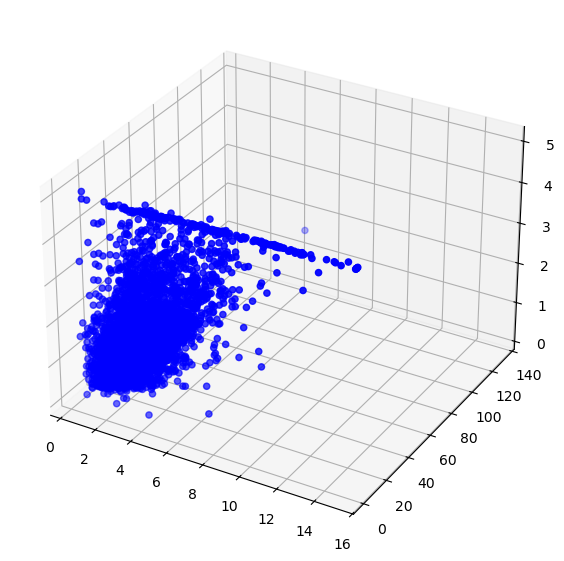

In [51]:
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(X_test['MedInc'], X_test['AveRooms'],
           y_test, color='blue', label='Actual Data')

x1_range = np.linspace(X_test['MedInc'].min(), X_test['MedInc'].max(), 100)
x2_range = np.linspace(X_test['AveRooms'].min(), X_test['AveRooms'].max(), 100)
x1, x2 = np.meshgrid(x1_range, x2_range)

z = model.predict(np.c_[x1.ravel(), x2.ravel()]).reshape(x1.shape)

ax.plot_surface(x1, x2, z, color='red', alpha=0.5, rstride=100, cstride=100)

ax.set_xlabel('Median Income')
ax.set_ylabel('Average Rooms')
ax.set_zlabel('House Price')
ax.set_title('Multiple Linear Regression Best Fit Line (3D)')

plt.show()

# Wine quality

In [62]:
# load dataset
red = pd.read_csv('../Datasets/winequality-red.csv', sep=';')
white = pd.read_csv('../Datasets/winequality-white.csv', sep=';')
print(red.shape)
white.shape

(1599, 12)


(4898, 12)

In [63]:
red.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [64]:
white.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6


In [65]:
red.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [66]:
white .info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4898 entries, 0 to 4897
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         4898 non-null   float64
 1   volatile acidity      4898 non-null   float64
 2   citric acid           4898 non-null   float64
 3   residual sugar        4898 non-null   float64
 4   chlorides             4898 non-null   float64
 5   free sulfur dioxide   4898 non-null   float64
 6   total sulfur dioxide  4898 non-null   float64
 7   density               4898 non-null   float64
 8   pH                    4898 non-null   float64
 9   sulphates             4898 non-null   float64
 10  alcohol               4898 non-null   float64
 11  quality               4898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 459.3 KB


In [67]:
# summary stats
red.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [68]:
# white summary stats
white.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000,4898.000000
mean,6.854788,0.278241,0.334192,6.391415,0.045772,35.308085,138.360657,0.994027,3.188267,0.489847,10.514267,5.877909
std,0.843868,0.100795,0.121020,5.072058,0.021848,17.007137,42.498065,0.002991,0.151001,0.114126,1.230621,0.885639
min,3.800000,0.080000,0.000000,0.600000,0.009000,2.000000,9.000000,0.987110,2.720000,0.220000,8.000000,3.000000
25%,6.300000,0.210000,0.270000,1.700000,0.036000,23.000000,108.000000,0.991723,3.090000,0.410000,9.500000,5.000000
50%,6.800000,0.260000,0.320000,5.200000,0.043000,34.000000,134.000000,0.993740,3.180000,0.470000,10.400000,6.000000
75%,7.300000,0.320000,0.390000,9.900000,0.050000,46.000000,167.000000,0.996100,3.280000,0.550000,11.400000,6.000000
max,14.200000,1.100000,1.660000,65.800000,0.346000,289.000000,440.000000,1.038980,3.820000,1.080000,14.200000,9.000000


In [69]:
# check missing values
red.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

In [70]:
white.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

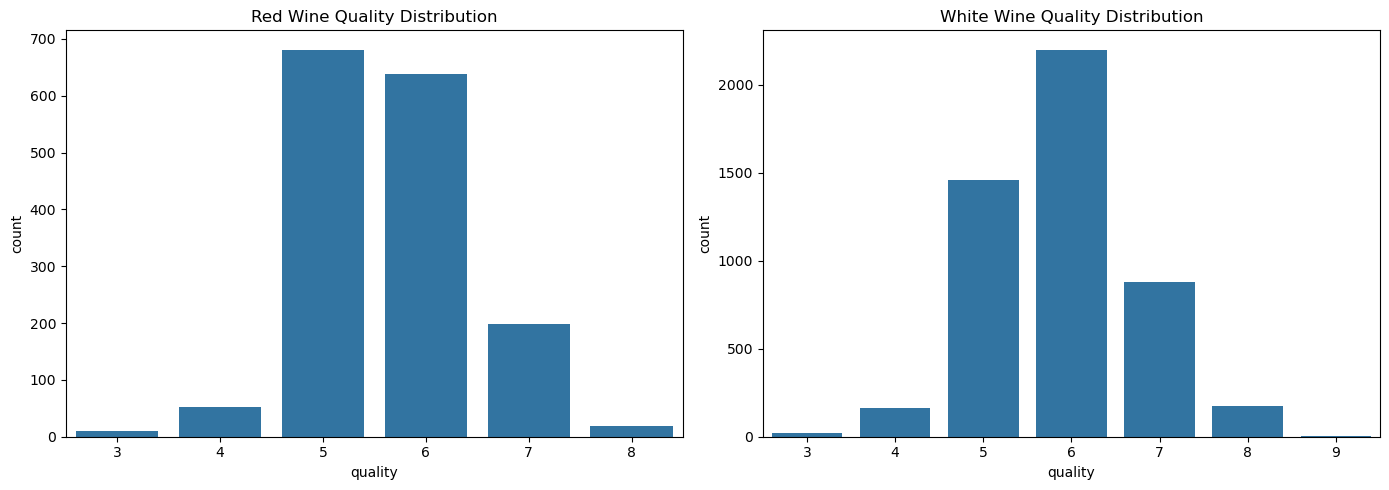

In [72]:
# quality distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=red, x='quality', ax=axes[0])
axes[0].set_title('Red Wine Quality Distribution')

sns.countplot(data=white, x='quality', ax=axes[1])
axes[1].set_title('White Wine Quality Distribution')

plt.tight_layout()
plt.show()

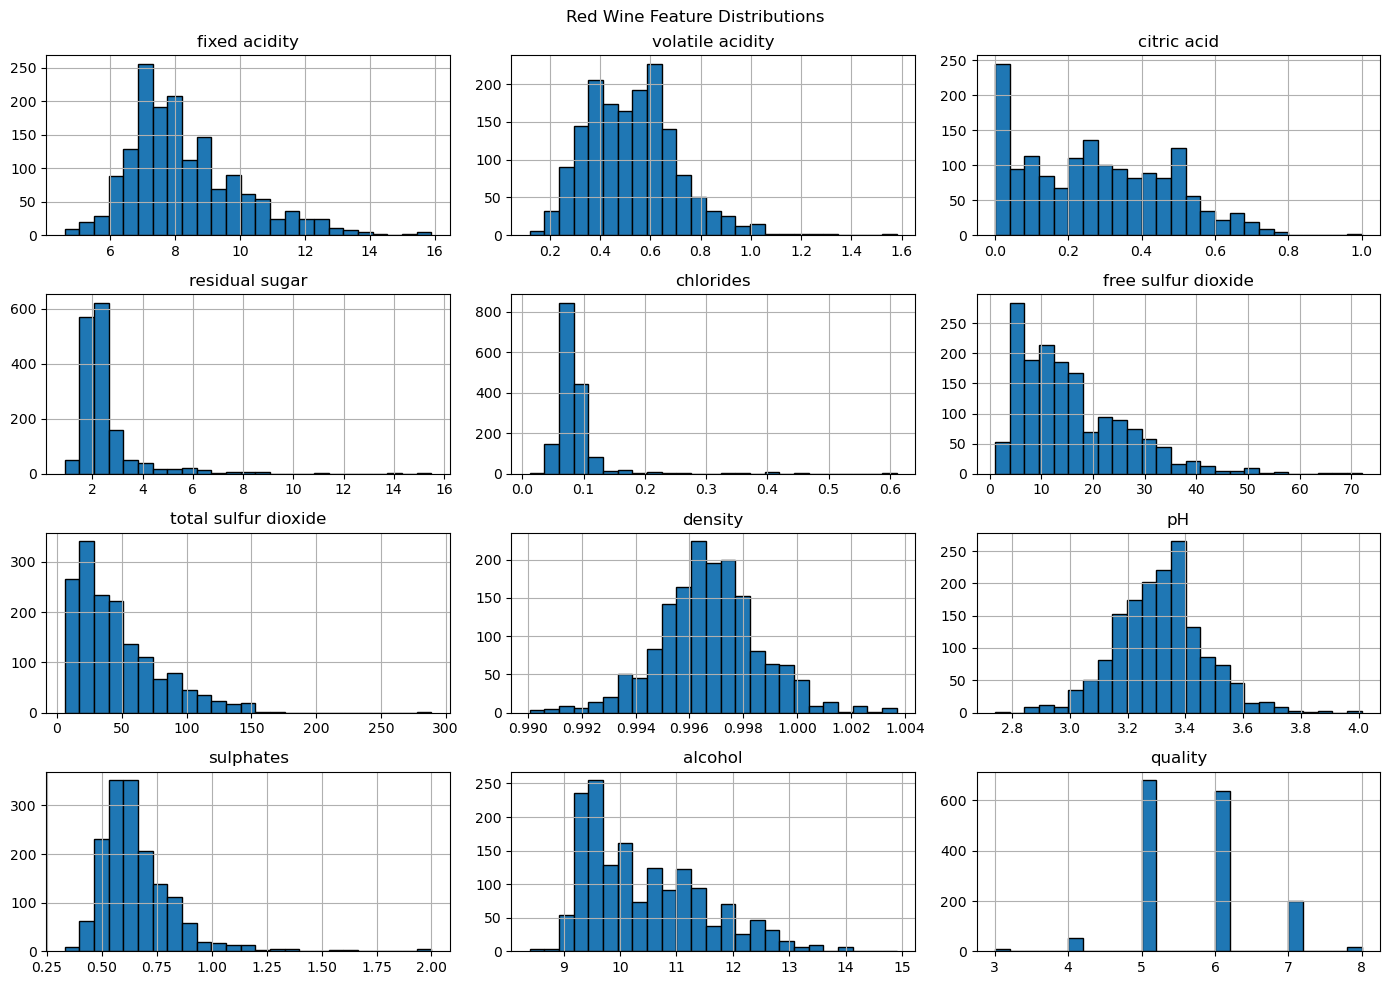

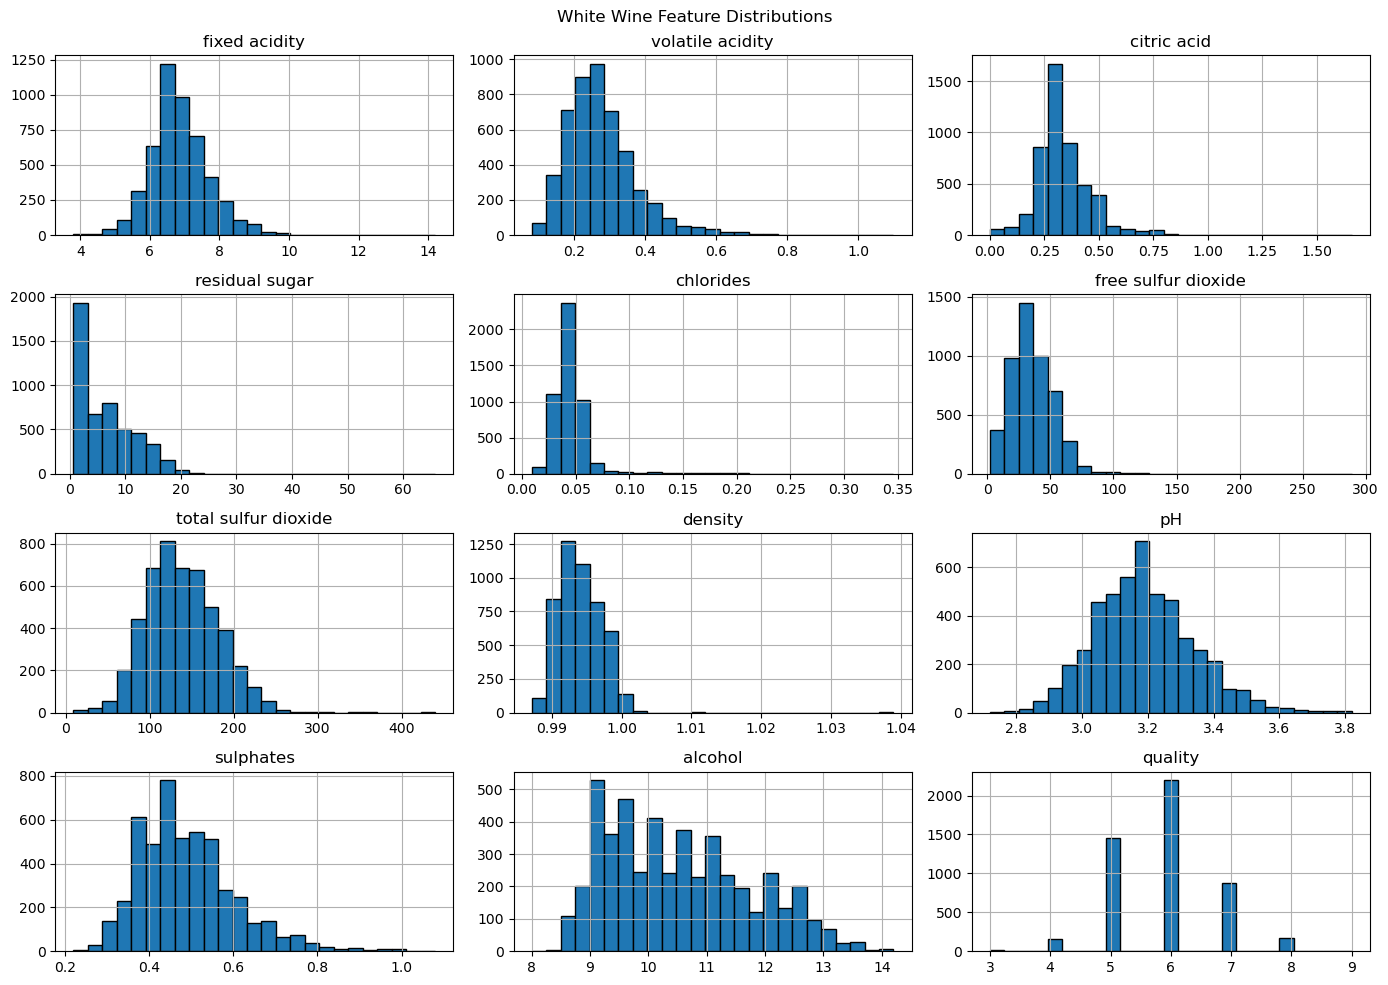

In [73]:
# feature distibutions
red.hist(figsize=(14, 10), bins=25, edgecolor='black')
plt.suptitle('Red Wine Feature Distributions')
plt.tight_layout()
plt.show()

white.hist(figsize=(14, 10), bins=25, edgecolor='black')
plt.suptitle('White Wine Feature Distributions')
plt.tight_layout()
plt.show()

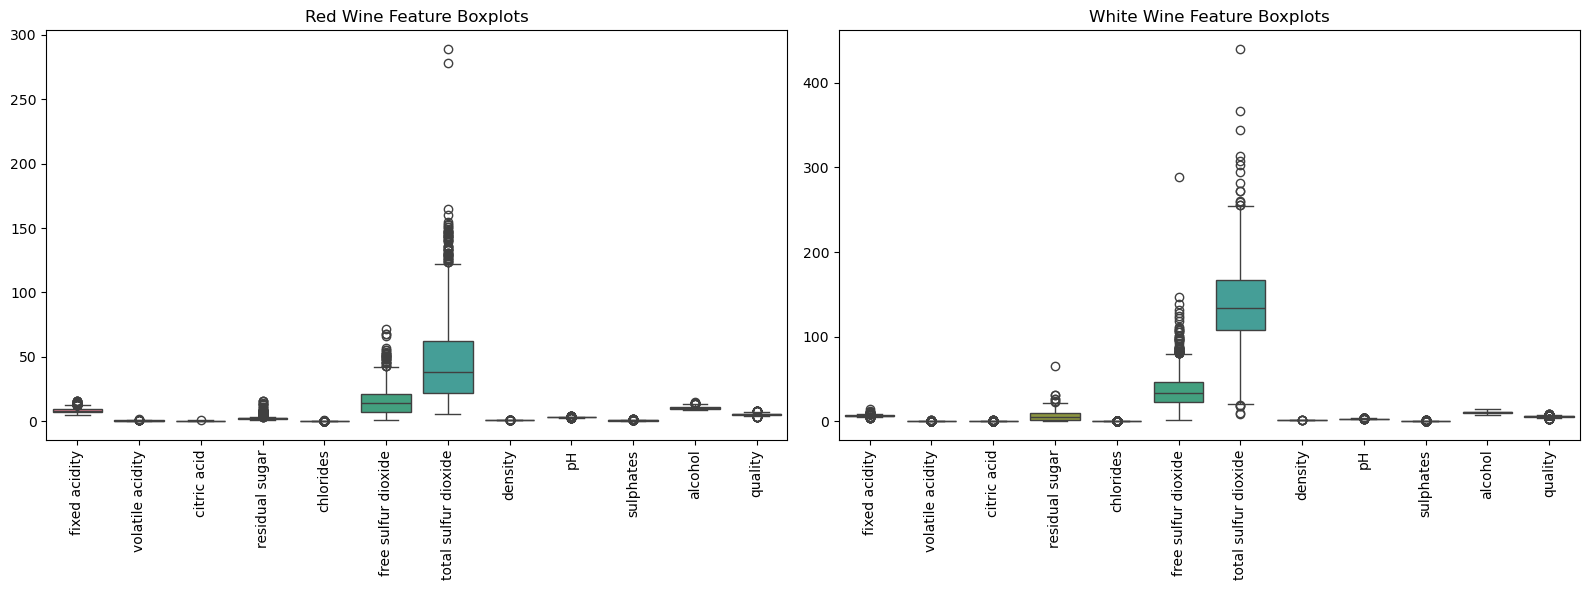

In [74]:
# outlier detection
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.boxplot(data=red, ax=axes[0])
axes[0].set_title('Red Wine Feature Boxplots')
axes[0].tick_params(axis='x', rotation=90)

sns.boxplot(data=white, ax=axes[1])
axes[1].set_title('White Wine Feature Boxplots')
axes[1].tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()

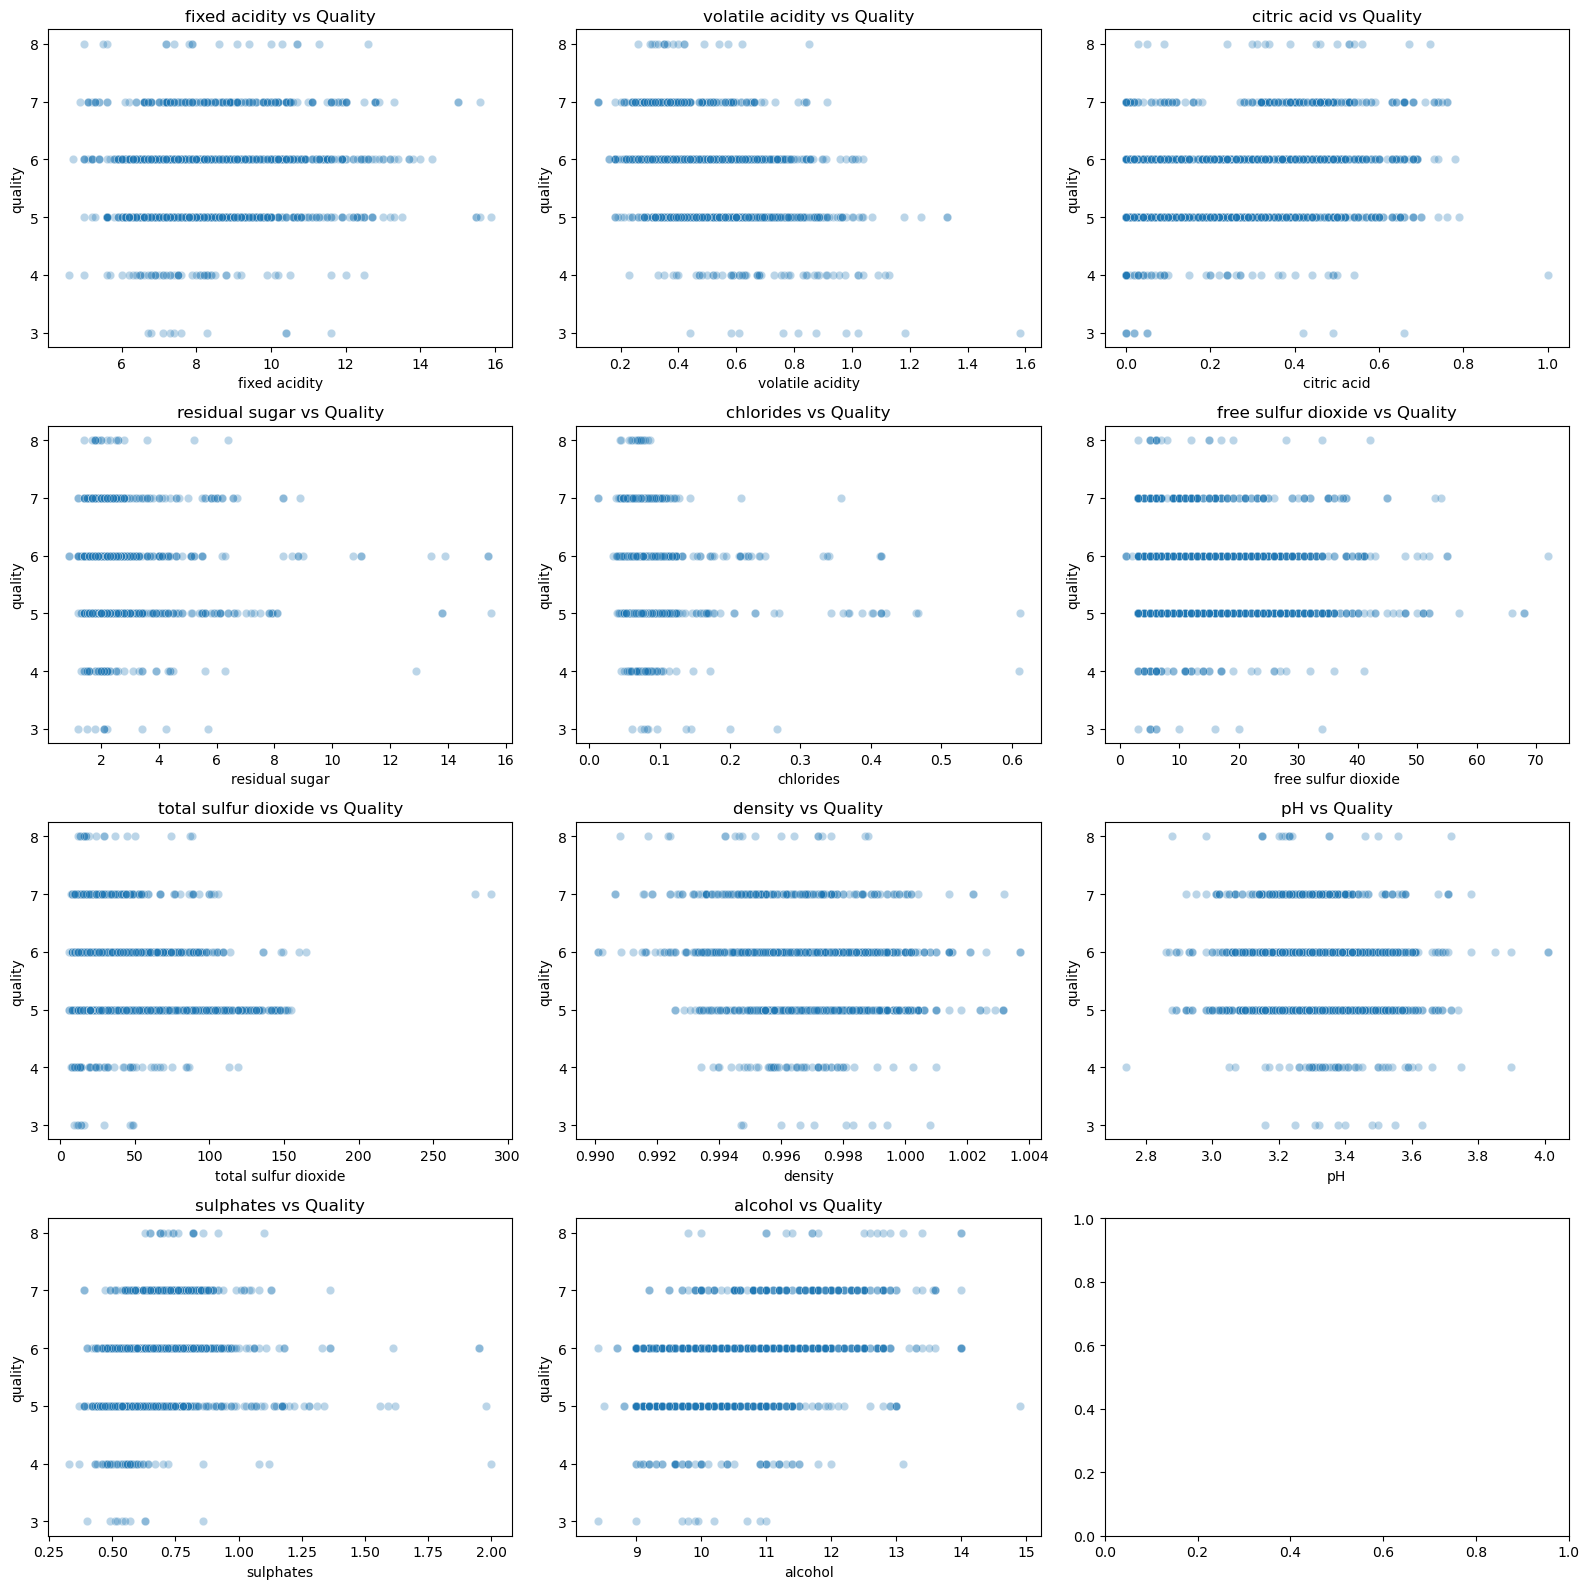

In [75]:
# Features vs quality
features = red.drop(columns='quality').columns

fig, axes = plt.subplots(4, 3, figsize=(16, 16))

for ax, feature in zip(axes.flat, features):
    sns.scatterplot(data=red, x=feature, y='quality', alpha=0.3, ax=ax)
    ax.set_title(f'{feature} vs Quality')

plt.tight_layout()
plt.show()

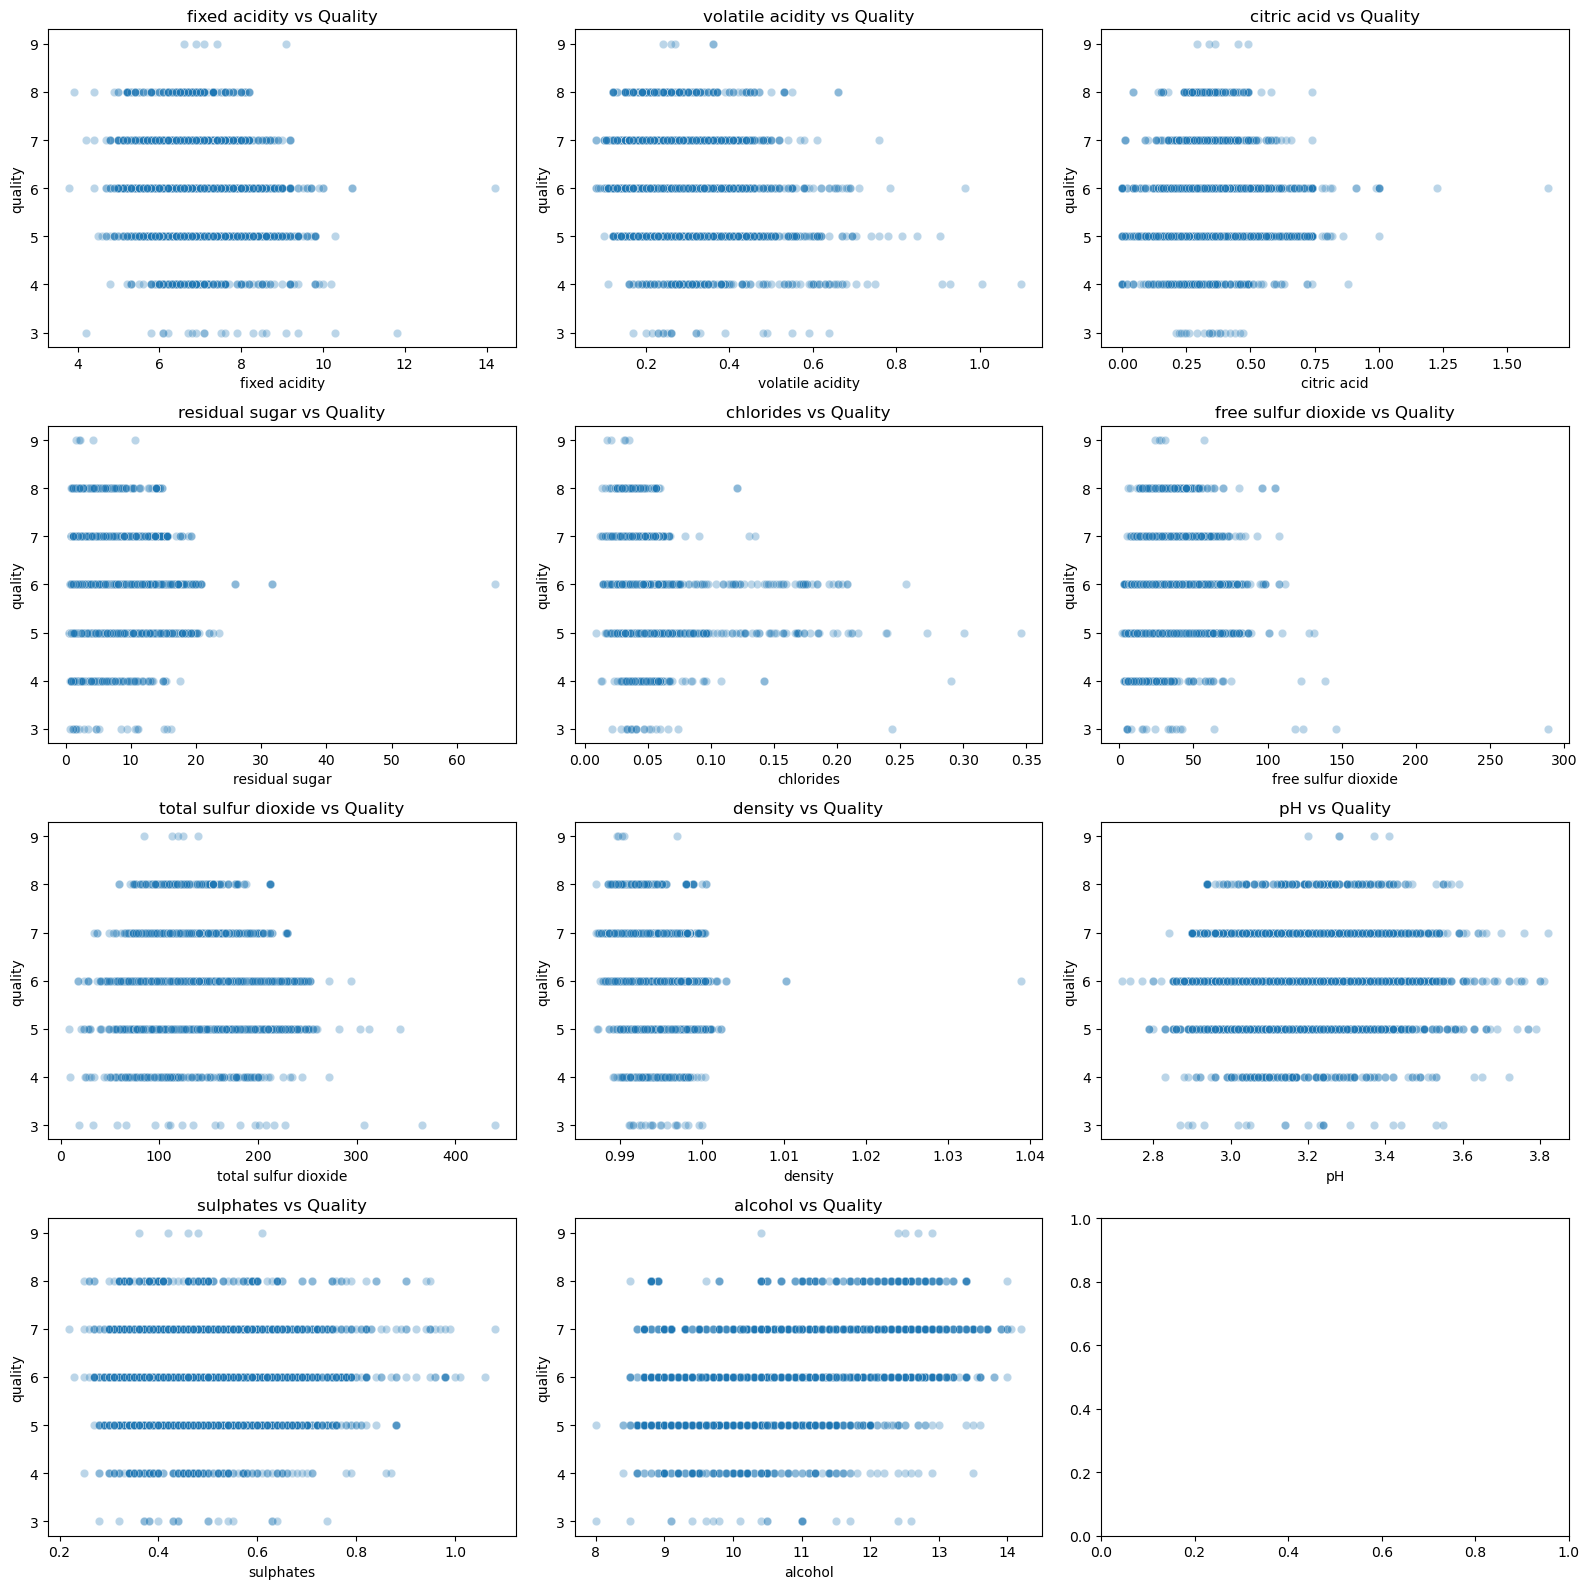

In [76]:
features = white.drop(columns='quality').columns

fig, axes = plt.subplots(4, 3, figsize=(16, 16))

for ax, feature in zip(axes.flat, features):
    sns.scatterplot(data=white, x=feature, y='quality', alpha=0.3, ax=ax)
    ax.set_title(f'{feature} vs Quality')

plt.tight_layout()
plt.show()

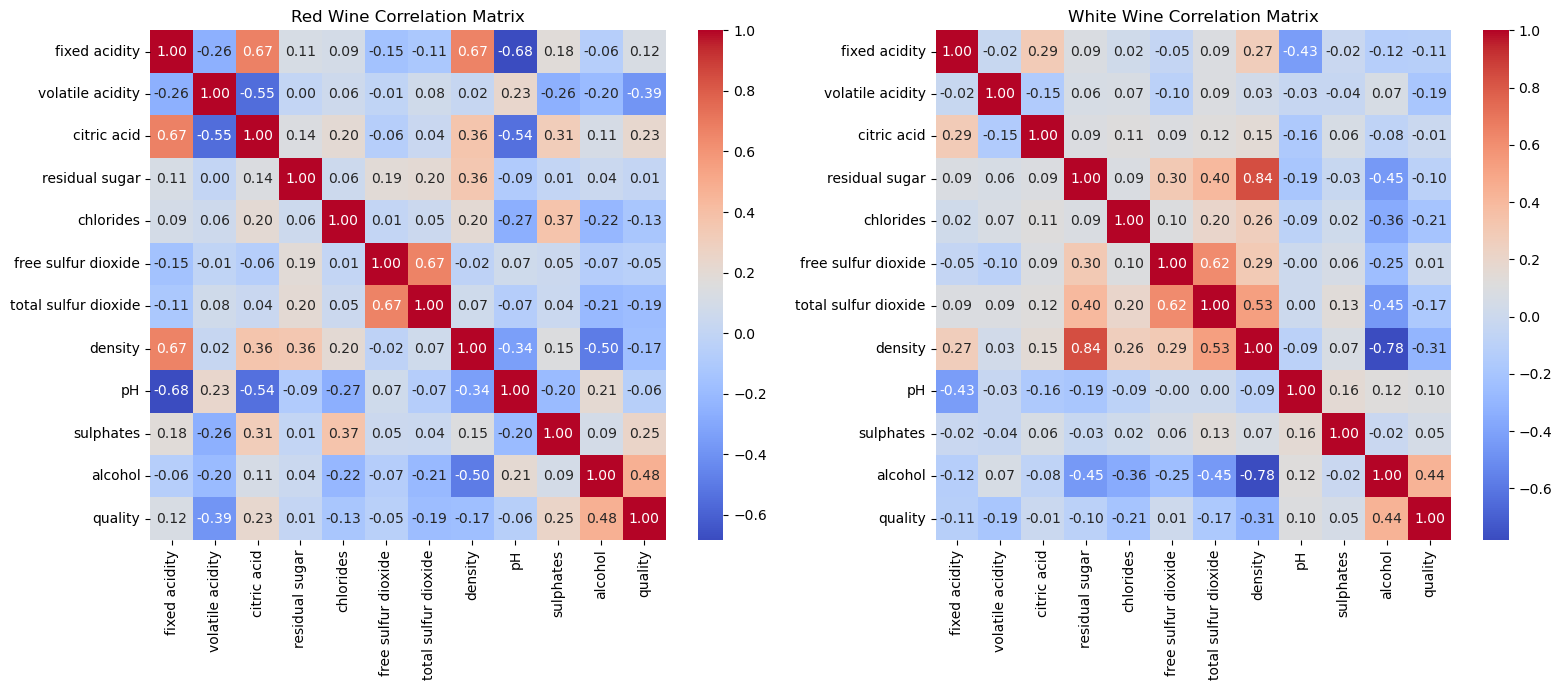

In [77]:
# correlation analysis
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(red.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[0])
axes[0].set_title('Red Wine Correlation Matrix')

sns.heatmap(white.corr(), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[1])
axes[1].set_title('White Wine Correlation Matrix')

plt.tight_layout()
plt.show()

In [78]:
# preprocessing
# features and target
X_red = red.drop(columns='quality')
y_red = red['quality']

X_white = white.drop(columns='quality')
y_white = white['quality']

In [79]:
# split dataset
X_red_train, X_red_test, y_red_train, y_red_test = train_test_split(X_red, y_red, test_size=0.2, random_state=42)

X_white_train, X_white_test, y_white_train, y_white_test = train_test_split(X_white, y_white, test_size=0.2, random_state=42)

In [80]:
# Red wine model
red_model = LinearRegression()
red_model.fit(X_red_train, y_red_train)
red_train_pred = red_model.predict(X_red_train)
red_test_pred = red_model.predict(X_red_test)

# White wine model
white_model = LinearRegression()
white_model.fit(X_white_train, y_white_train)
white_train_pred = white_model.predict(X_white_train)
white_test_pred = white_model.predict(X_white_test)

In [81]:
# Evaluation
def evaluate_model(y_train, train_pred, y_test, test_pred):
    return {
        'Train MAE': mean_absolute_error(y_train, train_pred),
        'Test MAE': mean_absolute_error(y_test, test_pred),
        'Train RMSE': np.sqrt(mean_squared_error(y_train, train_pred)),
        'Test RMSE': np.sqrt(mean_squared_error(y_test, test_pred)),
        'Train R²': r2_score(y_train, train_pred),
        'Test R²': r2_score(y_test, test_pred)
    }

results = pd.DataFrame({
    'Red Wine': evaluate_model(
        y_red_train, red_train_pred, y_red_test, red_test_pred
    ),
    'White Wine': evaluate_model(
        y_white_train, white_train_pred, y_white_test, white_test_pred
    )
})

results

,Red Wine,White Wine
Train MAE,0.499620,0.582647
Test MAE,0.503530,0.586267
Train RMSE,0.651300,0.750217
Test RMSE,0.624520,0.754337
Train R²,0.347993,0.284313
Test R²,0.403180,0.265275


### Evaluation Observations

- The Linear Regression model performed better on red wine than white wine.
- Red wine achieved a testing R² of approximately 0.403, compared to 0.265 for white wine.
- Both models show relatively close training and testing errors.
- The low R² scores suggest that Linear Regression does not capture all the factors influencing wine quality.

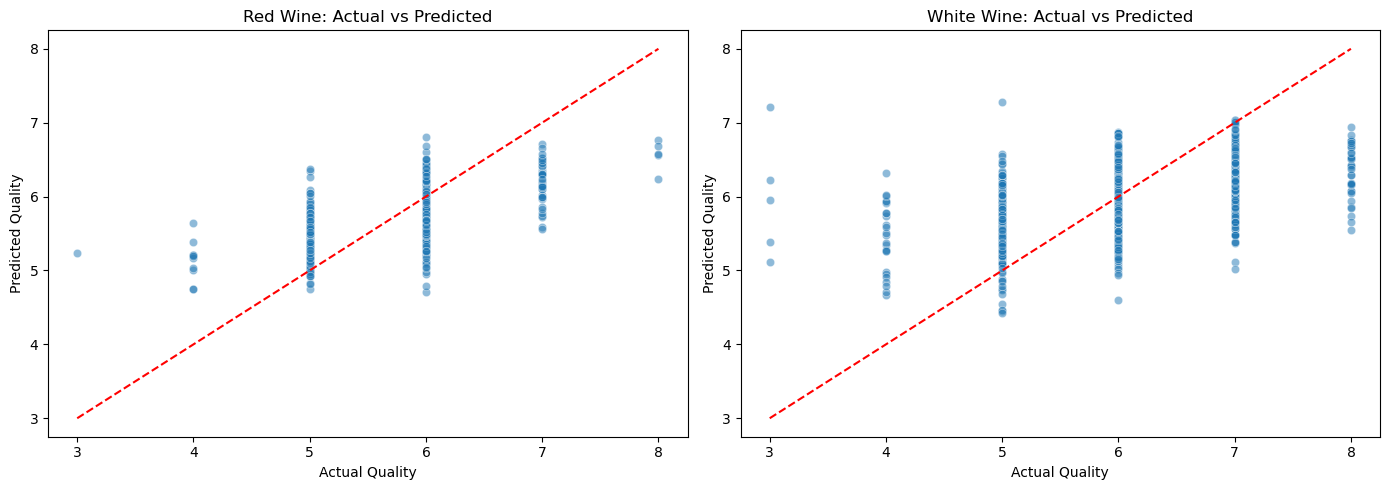

In [82]:
# Actual vs predicted
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=y_red_test, y=red_test_pred, alpha=0.5, ax=axes[0])
axes[0].plot([y_red_test.min(), y_red_test.max()],
             [y_red_test.min(), y_red_test.max()], 'r--')
axes[0].set_title('Red Wine: Actual vs Predicted')
axes[0].set_xlabel('Actual Quality')
axes[0].set_ylabel('Predicted Quality')

sns.scatterplot(x=y_white_test, y=white_test_pred, alpha=0.5, ax=axes[1])
axes[1].plot([y_white_test.min(), y_white_test.max()],
             [y_white_test.min(), y_white_test.max()], 'r--')
axes[1].set_title('White Wine: Actual vs Predicted')
axes[1].set_xlabel('Actual Quality')
axes[1].set_ylabel('Predicted Quality')

plt.tight_layout()
plt.show()

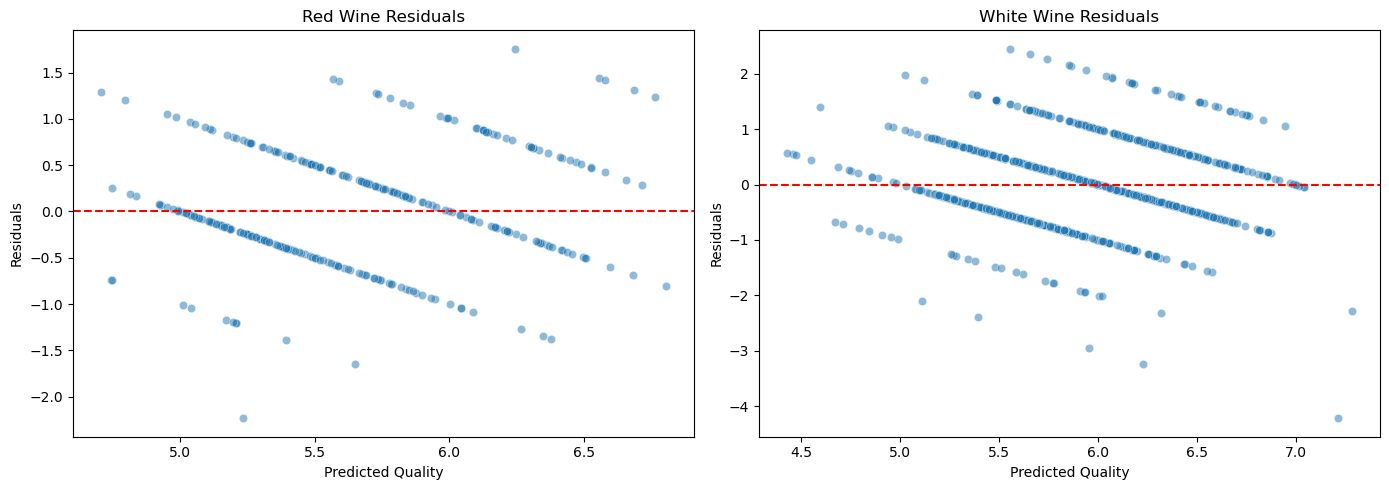

In [83]:
# Residual analysis
red_residuals = y_red_test - red_test_pred
white_residuals = y_white_test - white_test_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(x=red_test_pred, y=red_residuals, alpha=0.5, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_title('Red Wine Residuals')
axes[0].set_xlabel('Predicted Quality')
axes[0].set_ylabel('Residuals')

sns.scatterplot(x=white_test_pred, y=white_residuals, alpha=0.5, ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_title('White Wine Residuals')
axes[1].set_xlabel('Predicted Quality')
axes[1].set_ylabel('Residuals')

plt.tight_layout()
plt.show()

In [89]:
import statsmodels.api as sm

X_red_sm = sm.add_constant(X_red_train)

red_ols = sm.OLS(y_red_train, X_red_sm).fit()

print(red_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.348
Model:                            OLS   Adj. R-squared:                  0.342
Method:                 Least Squares   F-statistic:                     61.48
Date:                Mon, 26 Oct 2026   Prob (F-statistic):          1.48e-109
Time:                        04:06:01   Log-Likelihood:                -1266.4
No. Observations:                1279   AIC:                             2557.
Df Residuals:                    1267   BIC:                             2619.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   14.3551 

In [90]:
X_white_sm = sm.add_constant(X_white_train)

white_ols = sm.OLS(y_white_train, X_white_sm).fit()

print(white_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                quality   R-squared:                       0.284
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     141.1
Date:                Mon, 26 Oct 2026   Prob (F-statistic):          8.15e-274
Time:                        04:06:35   Log-Likelihood:                -4433.4
No. Observations:                3918   AIC:                             8891.
Df Residuals:                    3906   BIC:                             8966.
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                  124.3939 

### Regularization and Hyperparameter Tuning

In [92]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV

In [93]:
models = {
    'Ridge': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('model', Ridge())
        ]),
        'params': {
            'model__alpha': [0.01, 0.1, 1, 10, 100]
        }
    },

    'Lasso': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('model', Lasso(max_iter=10000))
        ]),
        'params': {
            'model__alpha': [0.001, 0.01, 0.1, 1, 10]
        }
    },

    'ElasticNet': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('model', ElasticNet(max_iter=10000))
        ]),
        'params': {
            'model__alpha': [0.001, 0.01, 0.1, 1, 10],
            'model__l1_ratio': [0.2, 0.5, 0.8]
        }
    }
}

In [94]:
# hyperparameter tuning
best_models = {}
tuning_results = []

for name, config in models.items():

    grid = GridSearchCV(
        estimator=config['pipeline'],
        param_grid=config['params'],
        cv=5,
        scoring='r2',
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    best_models[name] = grid.best_estimator_

    tuning_results.append({
        'Model': name,
        'Best Parameters': grid.best_params_,
        'Best CV R²': grid.best_score_
    })

tuning_results = pd.DataFrame(tuning_results)

tuning_results

,Model,Best Parameters,Best CV R²
0,Ridge,{'model__alpha': 0.01},0.611484
1,Lasso,{'model__alpha': 0.001},0.611487
2,ElasticNet,"{'model__alpha': 0.001, 'model__l1_ratio': 0.8}",0.611485


In [95]:
# Evaluate tuned models
regularized_results = []

for name, model in best_models.items():

    predictions = model.predict(X_test)

    regularized_results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predictions),
        'RMSE': np.sqrt(mean_squared_error(y_test, predictions)),
        'R²': r2_score(y_test, predictions)
    })

regularized_results = pd.DataFrame(regularized_results)

regularized_results

,Model,MAE,RMSE,R²
0,Ridge,0.533200,0.745581,0.575788
1,Lasso,0.533145,0.744642,0.576856
2,ElasticNet,0.533136,0.744752,0.576731


In [97]:
# Compare against ordinary Linear Regression
comparison = pd.DataFrame({
    'Model': ['Linear Regression'],
    'MAE': [mean_absolute_error(y_test, y_test_pred)],
    'RMSE': [np.sqrt(mean_squared_error(y_test, y_test_pred))],
    'R²': [r2_score(y_test, y_test_pred)]
})

comparison = pd.concat(
    [comparison, regularized_results],
    ignore_index=True
)

comparison.sort_values(by='R²', ascending=False)

,Model,MAE,RMSE,R²
2,Lasso,0.533145,0.744642,0.576856
3,ElasticNet,0.533136,0.744752,0.576731
1,Ridge,0.533200,0.745581,0.575788
0,Linear Regression,0.533200,0.745581,0.575788


### Regularization Results and Observations

- Lasso achieved the highest testing R² of approximately 0.577.
- ElasticNet performed similarly, with a testing R² of approximately 0.577.
- Ridge Regression produced the same performance as ordinary Linear Regression.
- Regularization resulted in only marginal improvements.
- These results suggest that regularization alone does not substantially improve this model's predictive performance.

In [101]:
# coefficient comparison
coefficient_comparison = pd.DataFrame({
    'Feature': df.drop(columns='MedHouseVal').columns,
    'Linear Regression': lr.coef_,
    'Ridge': best_models['Ridge'].named_steps['model'].coef_,
    'Lasso': best_models['Lasso'].named_steps['model'].coef_,
    'ElasticNet': best_models['ElasticNet'].named_steps['model'].coef_
})

coefficient_comparison

,Feature,Linear Regression,Ridge,Lasso,ElasticNet
0,MedInc,0.448675,0.854382,0.849140,0.850018
1,HouseAge,0.009724,0.122547,0.123346,0.123440
2,AveRooms,-0.123323,-0.294408,-0.281273,-0.283277
3,AveBedrms,0.783145,0.339257,0.326050,0.327895
4,Population,-0.000002,-0.002307,-0.001062,-0.001228
5,AveOccup,-0.003526,-0.040829,-0.039890,-0.040091
6,Latitude,-0.419792,-0.896921,-0.885822,-0.885542
7,Longitude,-0.433708,-0.869834,-0.858093,-0.857912


### Coefficient Analysis

- Regularization changed the coefficient values compared to ordinary Linear Regression.
- Ridge, Lasso and ElasticNet produced similar coefficient patterns.
- None of the Lasso coefficients were reduced to exactly zero, meaning no feature was completely eliminated.
- The regularized models retained the same general positive and negative coefficient directions.

Regularization controls coefficient magnitudes, helping reduce model complexity and potentially improve generalization.